Data Cleaning: Remove duplicates, handle missing reviews if any, preprocess text (lowercasing, stopwords removal).

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [42]:
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

In [43]:
df=pd.read_csv('amazonreviews.tsv',sep='\t')

In [44]:
df.head()

,label,review
0,pos,Stuning even for the non-gamer: This sound tra...
1,pos,The best soundtrack ever to anything.: I'm rea...
2,pos,Amazing!: This soundtrack is my favorite music...
3,pos,Excellent Soundtrack: I truly like this soundt...
4,pos,"Remember, Pull Your Jaw Off The Floor After He..."


In [45]:
df.isnull().sum()

,0
label,0
review,0


In [46]:
df.duplicated().sum()

np.int64(0)

In [47]:
#text processing
stop_words=set(ENGLISH_STOP_WORDS)

In [48]:
def process_text(text):
  if not isinstance(text,str):
    return ""
  text=text.lower()
  text=re.sub(r'<[^>]*>','',text)
  text=re.sub(r'[^a-z0-9\s]','',text)
  words=text.split()
  words=[w for w in words if w not in stop_words]
  return " ".join(words)

In [49]:
df['cleaned_review']=df['review'].apply(process_text)

In [50]:
df[['review','cleaned_review']].head()

,review,cleaned_review
0,Stuning even for the non-gamer: This sound tra...,stuning nongamer sound track beautiful paints ...
1,The best soundtrack ever to anything.: I'm rea...,best soundtrack im reading lot reviews saying ...
2,Amazing!: This soundtrack is my favorite music...,amazing soundtrack favorite music time hands i...
3,Excellent Soundtrack: I truly like this soundt...,excellent soundtrack truly like soundtrack enj...
4,"Remember, Pull Your Jaw Off The Floor After He...",remember pull jaw floor hearing youve played g...


In [51]:
from wordcloud import WordCloud
from collections import Counter

/tmp/ipykernel_604/2980217664.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df,x='label',palette={'pos':'green','neg':'red'})


Text(0.5, 1.0, 'Sentiment Distribution')

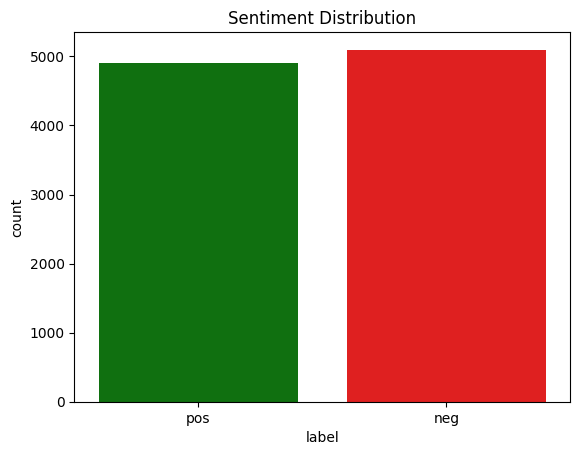

In [52]:
dist=df['label'].value_counts()
sns.countplot(data=df,x='label',palette={'pos':'green','neg':'red'})
plt.title('Sentiment Distribution')

In [53]:
pos_reviews=" ".join(df[df['label']=='pos']['cleaned_review'])
neg_reviews=" ".join(df[df['label']=='neg']['cleaned_review'])

In [54]:
pos_counts=Counter(pos_reviews.split())
neg_counts=Counter(neg_reviews.split())

In [55]:
top_pos=pos_counts.most_common(10)
top_neg=neg_counts.most_common(10)

In [56]:
print("Sentiment Distribution:")
print(dist)
print("\nTop 10 Positive Words (Count):")
for word,count in top_pos:
    print(f"{word}:{count}")
print("\nTop 10 Negative Words (Count):")
for word,count in top_neg:
    print(f"{word}:{count}")

Sentiment Distribution:
label
neg    5097
pos    4903
Name: count, dtype: int64

Top 10 Positive Words (Count):
book:3313
great:2087
good:1635
read:1553
like:1268
movie:1079
just:1022
love:902
time:871
really:827

Top 10 Negative Words (Count):
book:3183
like:1546
just:1507
movie:1464
dont:1240
read:1187
good:1134
time:1032
buy:814
really:778


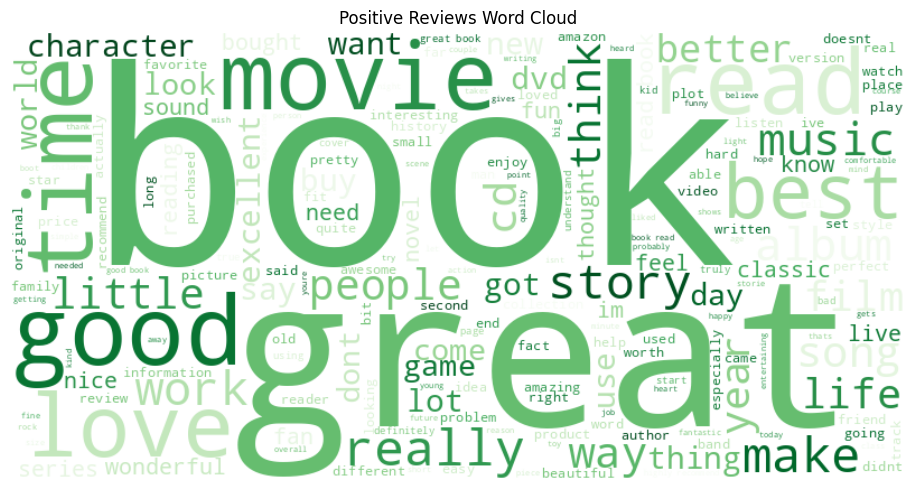

In [57]:
#Word clouds
wc_pos=WordCloud(width=800,height=400,background_color='white',colormap='Greens').generate(pos_reviews)
plt.figure(figsize=(10,5))
plt.imshow(wc_pos,interpolation='bilinear')
plt.axis('off')
plt.title('Positive Reviews Word Cloud')
plt.tight_layout()

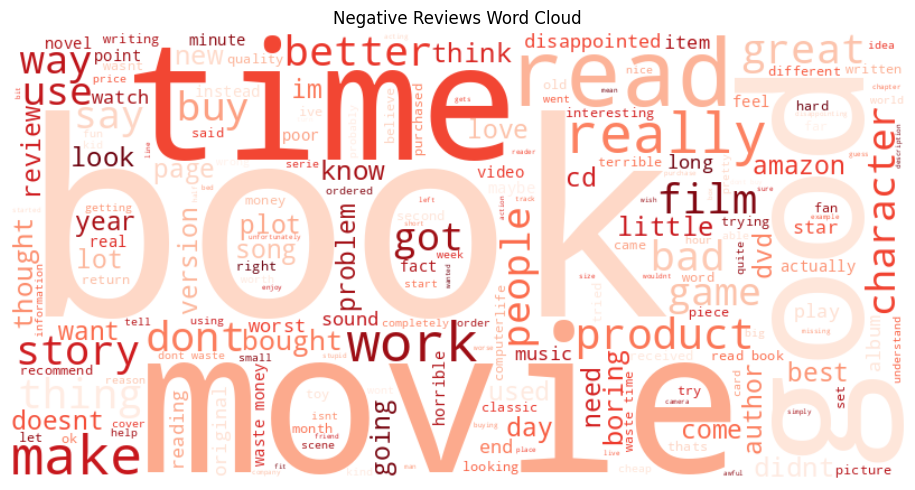

In [58]:
wc_neg=WordCloud(width=800,height=400,background_color='white',colormap='Reds').generate(neg_reviews)
plt.figure(figsize=(10,5))
plt.imshow(wc_neg,interpolation='bilinear')
plt.axis('off')
plt.title('Negative Reviews Word Cloud')
plt.tight_layout()

Model Development: Use NLP techniques (TF-IDF, Word2Vec, or BERT embeddings) with models like Logistic Regression, SVM, or Neural Networks.

In [62]:
x=df['cleaned_review']
y=df['label']

In [59]:
#decided to use TF-IDF nlp technique and logestic regression model
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

In [65]:
tfidf = TfidfVectorizer(max_features=5000)
model = LogisticRegression(max_iter=1000, random_state=42)
x_vec = tfidf.fit_transform(x)

Validation: Use train/test split, cross-validation, and metrics like accuracy, F1-score.

In [69]:
x_train,x_test,y_train,y_test=train_test_split(
    x_vec,y,test_size=0.2,random_state=42,stratify=y
)

In [70]:
model.fit(x_train,y_train)
y_pred=model.predict(x_test)

In [71]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

         neg       0.84      0.86      0.85      1019
         pos       0.85      0.84      0.84       981

    accuracy                           0.85      2000
   macro avg       0.85      0.85      0.85      2000
weighted avg       0.85      0.85      0.85      2000



In [72]:
#cross-validation
from sklearn.model_selection import cross_val_score, StratifiedKFold

In [73]:
kfold=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

In [74]:
y_binary=y.map({'pos': 1,'neg': 0})

In [75]:
cv_accuracy=cross_val_score(model,x_vec,y,cv=kfold,scoring='accuracy')
cv_f1=cross_val_score(model,x_vec,y_binary,cv=kfold,scoring='f1')

In [77]:
print(f"Mean Accuracy: {np.mean(cv_accuracy):.4f}")
print(f"Mean F1-Score: {np.mean(cv_f1):.4f}")

Mean Accuracy: 0.8492
Mean F1-Score: 0.8467
